# Assignment 6 Model Training

In [23]:
# show all ouputs in a cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.linear_model import SGDRegressor
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn import datasets
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score

import kagglehub
from sklearn.model_selection import GridSearchCV


## Question 1

1. Create a function to “manually” implement batch gradient descent algorithm for simple linear regression. The function will take the following arguments and output the estimated intercept and coefficient.

Arguments:

eta: learning rate (default to 0.01)

n_iterations: number of iterations (default to 1000)

x_b: feature plus ones

y: target

In particular, generate some random data for x_b and y as follows:

x = 3 * np.random.rand(2000, 1)

y = -10 - 5 * x + np.random.randn(2000, 1)

x_b = np.c_[np.ones((2000, 1)), x]


In [17]:
np.random.seed(1018)

x = 3 * np.random.rand(2000, 1)
y = -10 - 5 * x + np.random.randn(2000, 1)
x_b = np.c_[np.ones((2000, 1)), x]

In [18]:
def batch_gradient_descent(X, y, eta=0.01, n_iterations=1000):
    m = len(y)
    theta = np.zeros((X.shape[1], 1))

    for iteration in range(n_iterations):
        predictions = X @ theta
        errors = predictions - y
        gradients = (2 / m) * X.T @ errors
        theta = theta - eta * gradients

    return theta[0, 0], theta[1, 0]

In [19]:
intercept, coefficient = batch_gradient_descent(x_b, y)

print("Estimated intercept:", intercept)
print("Estimated coefficient:", coefficient)

Estimated intercept: -9.949591289271279
Estimated coefficient: -5.005011163556203


## Question 2

Generate some random data as below.

generate some data



In [6]:
np.random.seed(42)

m = 2000
X = 5 * np.random.rand(m, 1) - 2
y = -2 + 0.5 * X - 1.5 * X ** 2 + np.random.randn(m, 1)

# add features
poly_features = PolynomialFeatures(degree = 2, include_bias = False)
X_poly = poly_features.fit_transform(X)

### Question 2 (1)

(1) Fit a linear regression with polynomial terms. Report the estimated intercept and coefficients.

In [8]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)

print("Intercept:", lin_reg.intercept_)
print("Coefficients:", lin_reg.coef_)

LinearRegression()

Intercept: [-1.98692777]
Coefficients: [[ 0.52046311 -1.50653021]]


### Question 2 (2)

(2) Plot a scatter plot between X and y and overlay with the fitted curve.

Text(0.5, 0, 'X')

Text(0, 0.5, 'y')

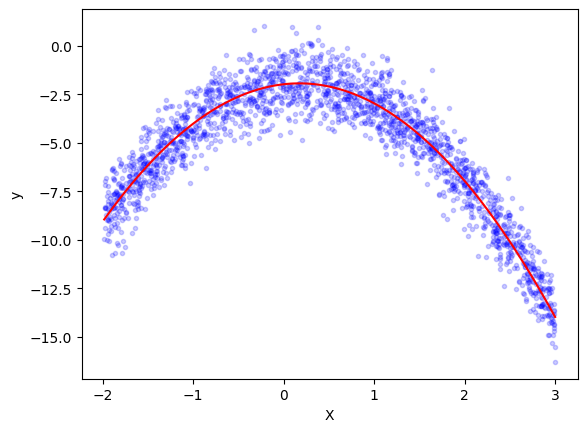

In [9]:
# Sort X and its corresponding predictions by X
new_X, new_y_pred = zip(*sorted(zip(X, lin_reg.predict(X_poly))))

# Plot the observed data and fitted curve
plt.plot(X, y, 'b.', alpha=0.2)
plt.plot(new_X, new_y_pred, 'r-')

plt.xlabel("X")
plt.ylabel("y")
plt.show()

### Question 2 (3)

(3) Pot the learning curve based on the second-degree polynomial regression.

In [10]:
X_train, X_val, y_train, y_val = train_test_split(
    X_poly, y, test_size=0.2, random_state=42
)

train_errors = []
val_errors = []
train_sizes = range(2, len(X_train) + 1, 10)

model = LinearRegression()

for n in train_sizes:

    model.fit(X_train[:n], y_train[:n])

    train_pred = model.predict(X_train[:n])
    val_pred = model.predict(X_val)

    train_errors.append(
        mean_squared_error(y_train[:n], train_pred)
    )
    val_errors.append(
        mean_squared_error(y_val, val_pred)
    )

LinearRegression()

LinearRegression()

LinearRegression()

LinearRegression()

LinearRegression()

...

LinearRegression()

LinearRegression()

LinearRegression()

LinearRegression()

LinearRegression()

Text(0.5, 0, 'Number of training observations')

Text(0, 0.5, 'RMSE')

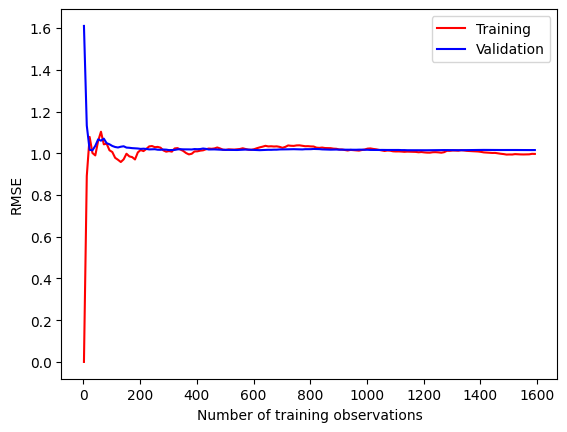

In [11]:
plt.plot(train_sizes, np.sqrt(train_errors), 'r-', label="Training")
plt.plot(train_sizes, np.sqrt(val_errors), 'b-', label="Validation")

plt.xlabel("Number of training observations")
plt.ylabel("RMSE")
plt.legend()
plt.show()

### Question 2 (4)

(4) Plot the learning curve based on the 15-degree polynomial regression.

In [12]:
poly_features = PolynomialFeatures(degree = 15, include_bias = False)
X_poly15 = poly_features.fit_transform(X)

In [13]:
X_train, X_val, y_train, y_val = train_test_split(
    X_poly15, y, test_size=0.2, random_state=42
)

train_errors = []
val_errors = []
train_sizes = range(2, len(X_train) + 1, 10)

model = LinearRegression()

for n in train_sizes:

    model.fit(X_train[:n], y_train[:n])

    train_pred = model.predict(X_train[:n])
    val_pred = model.predict(X_val)

    train_errors.append(
        mean_squared_error(y_train[:n], train_pred)
    )
    val_errors.append(
        mean_squared_error(y_val, val_pred)
    )

LinearRegression()

LinearRegression()

LinearRegression()

LinearRegression()

LinearRegression()

...

LinearRegression()

LinearRegression()

LinearRegression()

LinearRegression()

LinearRegression()

Text(0.5, 0, 'Number of training observations')

Text(0, 0.5, 'RMSE')

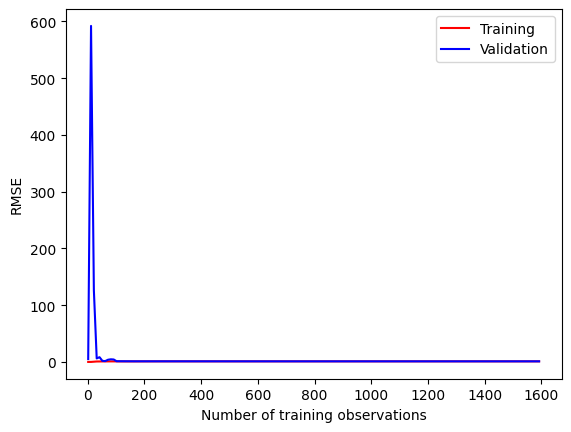

In [14]:
plt.plot(train_sizes, np.sqrt(train_errors), 'r-', label="Training")
plt.plot(train_sizes, np.sqrt(val_errors), 'b-', label="Validation")

plt.xlabel("Number of training observations")
plt.ylabel("RMSE")
plt.legend()
plt.show()

### Question 2 (5)

(5) Compare the above two learning curves. What is your conclusion regarding the potential overfitting of the 15-degree polynomial regression, and why?

**My answer:** The degree-15 model shows signs of overfitting with small training samples because its validation error is much higher than its training error. The gap shrinks with more data, but the plot’s scale makes the final errors hard to judge. The degree-2 model is more stable, with both errors settling near 1.

## Question 3

3. Generate some random data.

In [16]:
# generate X and y
np.random.seed(42)
X = -2 * np.random.rand(1000, 1)
y = 10 + 3 * X + np.random.randn(1000, 1)

### Question 3 (1)

(1) Fit a Ridge regression with stochastic gradient descent (hint: use SGDRegressor(penalty = 'l2')). Make a prediction for y when X = 2.77.

In [18]:
ridge_reg = SGDRegressor(penalty='l2', random_state=42)
ridge_reg.fit(X, y.ravel())

print("prediction for y when X = 2.77:", ridge_reg.predict([[2.77]]))

SGDRegressor(random_state=42)

prediction for y when X = 2.77: [18.45486496]


### Question 3 (2)

(2) Fit a Lasso regression with stochastic gradient descent (hint: use SGDRegressor(penalty = 'l1')). Make a prediction for y when X = 2.77.

In [19]:
lasso_reg = SGDRegressor(penalty='l1', random_state=42)
lasso_reg.fit(X, y.ravel())

print("prediction for y when X = 2.77:",lasso_reg.predict([[2.77]]))

SGDRegressor(penalty='l1', random_state=42)

prediction for y when X = 2.77: [18.45680891]


### Question 3 (3)

(3) Fit an Elastic Net using the following hyperparmaters: alpha = 0.1 and l1_ratio = 0.5. Make a prediction for y when X = 2.77.

In [20]:
elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic_net.fit(X, y.ravel())

print("prediction for y when X = 2.77:", elastic_net.predict([[2.77]]))

ElasticNet(alpha=0.1)

prediction for y when X = 2.77: [16.74379671]


## Question 4

4. The following tasks will use a dataset from Kaggle. The dataset can be downloaded from: https://www.kaggle.com/uciml/mushroom-classification

Context (from Kaggle):

Although this dataset was initially contributed to the UCI Machine Learning repository nearly 30 years ago, mushroom hunting (otherwise known as "shrooming") is enjoying new peaks in popularity. Learn which features spell death and which are most palatable in this dataset of mushroom characteristics. And how confident can your model be?

Content (from Kaggle):

This dataset includes descriptions of hypothetical samples corresponding to 23 species of gilled mushrooms in the Agaricus and Lepiota Family Mushroom drawn from The Audubon Society Field Guide to North American Mushrooms (1981). Each species is identified as definitely edible, definitely poisonous, or of unknown edibility and not recommended. This latter class was combined with the poisonous one. The Guide clearly states that there is no simple rule for determining the edibility of a mushroom. No rule like “leaflets three, let it be'” for Poisonous Oak and Ivy.

Features:

- cap-shape: bell=b,conical=c,convex=x,flat=f, knobbed=k,sunken=s

- cap-surface: fibrous=f,grooves=g,scaly=y,smooth=s

- cap-color: brown=n,buff=b,cinnamon=c,gray=g,green=r,pink=p,purple=u,red=e,white=w,yellow=y

- bruises: bruises=t,no=f

- odor: almond=a,anise=l,creosote=c,fishy=y,foul=f,musty=m,none=n,pungent=p,spicy=s

- gill-attachment: attached=a,descending=d,free=f,notched=n

- gill-spacing: close=c,crowded=w,distant=d

- gill-size: broad=b,narrow=n

- gill-color: black=k,brown=n,buff=b,chocolate=h,gray=g, green=r,orange=o,pink=p,purple=u,red=e,white=w,yellow=y

- stalk-shape: enlarging=e,tapering=t

- stalk-root: bulbous=b,club=c,cup=u,equal=e,rhizomorphs=z,rooted=r,missing=?

- stalk-surface-above-ring: fibrous=f,scaly=y,silky=k,smooth=s

- stalk-surface-below-ring: fibrous=f,scaly=y,silky=k,smooth=s

- stalk-color-above-ring: brown=n,buff=b,cinnamon=c,gray=g,orange=o,pink=p,red=e,white=w,yellow=y

- stalk-color-below-ring: brown=n,buff=b,cinnamon=c,gray=g,orange=o,pink=p,red=e,white=w,yellow=y

- veil-type: partial=p,universal=u

- veil-color: brown=n,orange=o,white=w,yellow=y

- ring-number: none=n,one=o,two=t

- ring-type: cobwebby=c,evanescent=e,flaring=f,large=l,none=n,pendant=p,sheathing=s,zone=z

- spore-print-color: black=k,brown=n,buff=b,chocolate=h,green=r,orange=o,purple=u,white=w,yellow=y

- population: abundant=a,clustered=c,numerous=n,scattered=s,several=v,solitary=y

- habitat: grasses=g,leaves=l,meadows=m,paths=p,urban=u,waste=w,woods=d

Target:

class: edible=e, poisonous=p



### Question 4 (1)

(1) Read the data into Google Colab using .read_csv() function.

In [3]:
# Download latest version
path = kagglehub.dataset_download("uciml/mushroom-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mushroom-classification' dataset.
Path to dataset files: /kaggle/input/mushroom-classification


In [4]:
data = pd.read_csv(path + '/mushrooms.csv')

### Question 4 (2)

(2) Print the first and last five rows of the dataframe using .head() and .tail() functions. How many observations (i.e., sample size) do you have in total?

In [5]:
data.head()
print("\n")
data.tail()
print("\n")
print("Number of observations:", len(data))

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l
8123,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,o,c,l




Number of observations: 8124


### Question 4 (3)

(3) Use .info() to get a short description of the dataframe.

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

### Question 4 (4)

(4) Take a look at the target (i.e., class) using .value_counts() function. What is the prevalence of edible mushrooms in the dataframe?

In [7]:
data['class'].value_counts()

,count
class,
e,4208
p,3916


In [8]:
edible_pct = data['class'].value_counts()['e'] / len(data) * 100
print("prevalence of edible mushrooms in the dataframe:", edible_pct)

prevalence of edible mushrooms in the dataframe: 51.7971442639094


### Question 4 (5)

(5) Split data into train and test sets, with the test set occupying 20% of the data.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    data.drop(columns = 'class'), data['class'], test_size=0.2, random_state=42
)


### Question 4 (6)

(6) Fit and transform the train set using the one-hot encoding of all categorical features (indeed, all features in the dataframe are categorical).

In [14]:
one_hot_encoder = OneHotEncoder()

X_train_prep = one_hot_encoder.fit_transform(X_train)

### Question 4 (7)

(7) Transform the test set using one-hot encoding.

In [15]:
X_test_prep = one_hot_encoder.transform(X_test)

### Question 4 (8)

(8) Fit a logistic regression on the train set.

In [16]:
# fit a logistic regression
log_reg = LogisticRegression()
log_reg.fit(X_train_prep, y_train)

LogisticRegression()

### Question 4 (9)

(9) Make predictions on the test set.

In [17]:
# make predictions
y_pred = log_reg.predict(X_test_prep)

### Question 4 (10)

(10) Report accuracy for the predictions.

In [18]:
# report accuarcy
accuracy_score(y_test, y_pred)

1.0

### Question 4 (11)

(11) Conduct a grid search for the logistic regression. Search values for one parameter only: C. Report the best parameter C value from the grid search. Use the best model as the final model, and evaluate that model on the test set. Report accuracy and compare it to the accuracy obtained from the initial model before the grid search. Do you see an improvement in terms of accuracy, and if so, by how much?

In [24]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(X_train_prep, y_train)

print("Best C:", grid_search.best_params_['C'])

GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=1000),
             param_grid={'C': [0.01, 0.1, 1, 10, 100]}, scoring='accuracy')

Best C: 1


In [26]:
# fit a logistic regression
log_reg_c  = LogisticRegression(C=1)
log_reg_c.fit(X_train_prep, y_train)

# make predictions
y_pred_c = log_reg_c.predict(X_test_prep)
print('\n')

# report accuarcy
accuracy_score(y_test, y_pred)

LogisticRegression(C=1)

1.0

The accuracies with and without regularization are both 1, which means there's no improvement in terms of accuracy.